# Recommandeur sémantique de vins Thème 5

Projet *Analyse sémantique et systèmes intelligents de recommandation* · ESME ING5 A3MSI 2026-27
Prototype **pédagogique** (public adulte, aucun achat) : on associe une description en langage naturel (goûts, occasion, repas) à des profils sensoriels de vins, par **similarité sémantique d'embeddings**.

> *L'abus d'alcool est dangereux pour la santé, à consommer avec modération.*

## Plan du notebook

| # | Section | Ce qu'on y fait |
|---|---|---|
| 1 | Mise en place | imports, thème graphique, choix du backend d'embeddings |
| 2 | Les données | 60 vins, structure imposée par le sujet |
| 3 | Le moteur | encodage du catalogue, profil global d'un vin |
| 4 | Embeddings : l'idée | texte → vecteur → similarité cosinus |
| 5 | Blocs de goût | référentiel (≙ « blocs de compétences ») et score d'un vin par bloc |
| 6 | Axes de structure | corps, acidité, douceur, tanins, intensité sans annotation manuelle |
| 7 | Le questionnaire | les réponses d'un utilisateur (cellule à modifier) |
| 8 | Recommandation | classement et profil détecté |
| 9 | **Le score, pas à pas** | recalcul à la main : affinité, couverture, pénalité |
| 10 | Explications | pourquoi tel vin est recommandé |
| 11 | Visualisations | radar, décomposition, carte sémantique, clusters |
| 12 | Sensibilité et filtres | effet des pondérations et des filtres durs |
| 13 | Évaluation | comparaison des backends sur 19 requêtes |
| 14 | Stockage, limites, éthique | |

Le moteur (`embeddings.py`, `wine_engine.py`) est dans le même dossier : le notebook sert à **comprendre, vérifier et illustrer** chaque étape.

## 1 · Mise en place

Prérequis : `pip install -r requirements.txt` (pandas, numpy, scikit-learn, matplotlib, sentence-transformers…).
Le backend est choisi dans la cellule suivante : `"auto"` essaie **SBERT** (modèle multilingue, ~0,5 Go téléchargés au premier lancement) et bascule sur **LSA** (hors-ligne) s'il est indisponible.

In [1]:
import sys, json, warnings, textwrap, importlib.util
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

warnings.filterwarnings("ignore")

# Le notebook peut être lancé depuis le dossier du projet ou depuis son parent.
ROOT = Path.cwd().resolve()
for cand in (ROOT, ROOT / "wine_semantic_recommender"):
    if (cand / "wine_engine.py").exists():
        ROOT = cand
        break
else:
    raise FileNotFoundError("Lancez ce notebook depuis le dossier qui contient wine_engine.py")
sys.path.insert(0, str(ROOT))

from embeddings import load_backend
from wine_engine import (AVOID_GAMMA, COMPONENT_LABELS, DEFAULT_WEIGHTS, Reference, UserInput,
                         WineEngine, level_of, load_wines)

# evaluate.py (jeu de 19 requêtes annotées) est chargé sous un nom unique, sans collision avec d'autres paquets.
_spec = importlib.util.spec_from_file_location("wine_evaluate", ROOT / "evaluate.py")
ev = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(ev)
print("Dossier du projet :", ROOT)

ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
# --- Thème graphique : palette catégorielle validée (couleur = entité, ordre fixe), séquentiel = un seul bleu ---
BG, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]       # bleu, orange, aqua, jaune, magenta
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
GRAY = AXIS
HALO = [pe.withStroke(linewidth=2.5, foreground=BG)]

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG, "figure.dpi": 110,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "legend.frameon": False, "legend.fontsize": 9,
})

BACKEND = "auto"     # "auto" (SBERT sinon LSA) | "sbert" | "spacy" | "lsa"
backend, notes = load_backend(BACKEND)
for n in notes:
    print("⚠", n)
print("Backend actif :", backend.label)
print("Famille       :", backend.kind)

⚠ Backend « sbert » indisponible (ModuleNotFoundError: No module named 'sentence_transformers').
Backend actif : LSA · TF-IDF + SVD (hors-ligne)
Famille       : Sémantique latente (TF-IDF + SVD)


## 2 · Les données

`data/wines.csv` contient **60 vins** avec les colonnes du sujet
`WineID | Category | Region | Description | SensoryProfile | FoodPairing | Keywords`,
plus `Name`, `Grape` et `PriceEUR` (nécessaire au filtre budget). Les descriptions sont rédigées pour la démo et **les prix sont fictifs**.

In [ ]:
wines = load_wines()
ref = Reference.load()

# Conformité avec le sujet
assert len(wines) >= 50, "le sujet demande au moins 50 références"
assert {"WineID", "Category", "Region", "Description", "SensoryProfile", "FoodPairing", "Keywords"} <= set(wines.columns)
assert wines["WineID"].is_unique and not wines.isna().any().any()
print(f"{len(wines)} vins · {wines['Category'].nunique()} catégories · {wines['Country'].nunique()} pays")
display(wines[["WineID", "Name", "Category", "Region", "Grape", "PriceEUR"]].head(8))
print("\nExemple de fiche complète :")
for col in ["Description", "SensoryProfile", "FoodPairing", "Keywords"]:
    print(f"  {col:15s} {wines.loc[0, col]}")

60 vins · 5 catégories · 10 pays


,WineID,Name,Category,Region,Grape,PriceEUR
0,W01,Saint-Estèphe,Rouge,Bordeaux (Médoc),"Cabernet-Sauvignon, Merlot",42
1,W02,Pauillac,Rouge,Bordeaux (Médoc),"Cabernet-Sauvignon, Merlot",80
2,W03,Saint-Émilion grand cru,Rouge,Bordeaux (rive droite),"Merlot, Cabernet franc",38
3,W04,Pomerol,Rouge,Bordeaux (rive droite),Merlot,95
4,W05,Bordeaux rouge,Rouge,Bordeaux,"Merlot, Cabernet-Sauvignon",9
5,W06,Gevrey-Chambertin,Rouge,Bourgogne (Côte de Nuits),Pinot noir,62
6,W07,Bourgogne Pinot noir,Rouge,Bourgogne,Pinot noir,22
7,W08,Beaujolais-Villages,Rouge,Beaujolais,Gamay,9



Exemple de fiche complète :
  Description     Rouge de Bordeaux structuré et sérieux, plutôt austère dans sa jeunesse. Sa trame tannique solide et sa belle fraîcheur en font un vin de garde, apprécié pour les repas de fête.
  SensoryProfile  cassis, mûre, cèdre, graphite, tabac, tanins fermes et serrés, corps puissant, longue finale
  FoodPairing     côte de bœuf grillée, entrecôte, gigot d'agneau rôti, gibier, fromages à pâte pressée
  Keywords        cabernet, cassis, cèdre, tanins, garde, charpenté, bordeaux


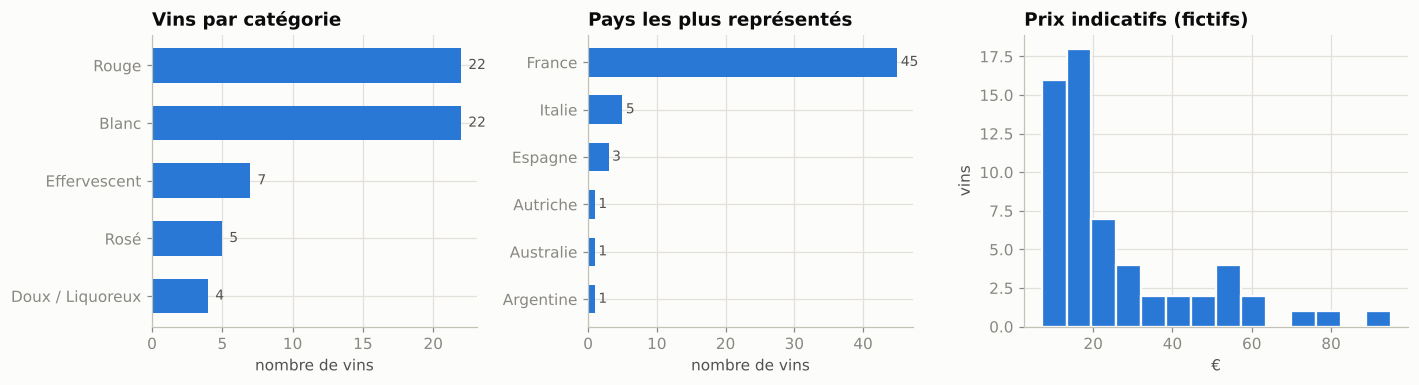

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.1, 1.1, 1.3]})
cat = wines["Category"].value_counts().sort_values()
axs[0].barh(cat.index, cat.values, color=SERIES[0], height=0.6)
axs[0].set_title("Vins par catégorie"); axs[0].set_xlabel("nombre de vins")
for y, v in enumerate(cat.values):
    axs[0].text(v + 0.5, y, str(v), va="center", fontsize=9, color=INK2)

ctry = wines["Country"].value_counts().head(6).sort_values()
axs[1].barh(ctry.index, ctry.values, color=SERIES[0], height=0.6)
axs[1].set_title("Pays les plus représentés"); axs[1].set_xlabel("nombre de vins")
for y, v in enumerate(ctry.values):
    axs[1].text(v + 0.5, y, str(v), va="center", fontsize=9, color=INK2)

axs[2].hist(wines["PriceEUR"], bins=14, color=SERIES[0], edgecolor=BG, linewidth=1.5)
axs[2].set_title("Prix indicatifs (fictifs)"); axs[2].set_xlabel("€"); axs[2].set_ylabel("vins")
plt.tight_layout(); plt.show()

## 3 · Le moteur : encoder le catalogue

Chaque vin est encodé en **trois vecteurs**, un par champ, plutôt qu'en un seul bloc de texte :

| Champ | Contenu | Sert à comparer avec… |
|---|---|---|
| description | catégorie + description | le texte libre / l'occasion |
| profil sensoriel | arômes, tanins, corps + mots-clés | les blocs de goût, les axes de structure |
| accords | `FoodPairing` | le repas de l'utilisateur |

Le **profil global** d'un vin combine description et profil sensoriel : $\;P = \text{norm}\,(0{,}4\cdot E_{desc} + 0{,}6\cdot E_{sens})\;$.
On encode les champs séparément pour rester sous la fenêtre de 128 tokens de SBERT et pour comparer chaque champ à la bonne entrée utilisateur.

In [ ]:
eng = WineEngine(wines, ref, backend)      # encode le catalogue, les blocs, les axes, calcule clusters et PCA

print("Dimension des embeddings :", eng.E_profile.shape[1])
print("E_desc, E_sens, E_food   :", eng.E_desc.shape, eng.E_sens.shape, eng.E_food.shape)
print("Vecteurs unitaires (norme 1) :", bool(np.allclose(np.linalg.norm(eng.E_profile, axis=1), 1)))

Dimension des embeddings : 40
E_desc, E_sens, E_food   : (60, 40) (60, 40) (60, 40)
Vecteurs unitaires (norme 1) : True


## 4 · Embeddings : l'idée en une cellule

Un **embedding** transforme un texte en vecteur de sorte que des textes de sens proche donnent des vecteurs proches. On mesure la proximité par la **similarité cosinus** (comme les vecteurs sont normalisés, c'est simplement un produit scalaire) :

$$\cos(a, b) = \frac{a \cdot b}{\lVert a\rVert\,\lVert b\rVert}$$

Les trois backends du projet (SBERT, spaCy, LSA) produisent ces vecteurs de façons différentes ; tout le reste du moteur est identique.

In [ ]:
phrases = [
    "un rouge puissant et tannique",
    "un vin corsé avec beaucoup de tanins",
    "un blanc léger et citronné",
    "des bulles fines pour fêter un événement",
]
V = eng.backend.encode(phrases)
sim = pd.DataFrame(V @ V.T, index=phrases, columns=[f"phrase {i+1}" for i in range(len(phrases))]).round(2)
print("Similarité cosinus entre 4 phrases (1 = identiques) :")
display(sim)

Similarité cosinus entre 4 phrases (1 = identiques) :


,phrase 1,phrase 2,phrase 3,phrase 4
un rouge puissant et tannique,1.00,0.27,-0.01,0.05
un vin corsé avec beaucoup de tanins,0.27,1.00,-0.04,0.04
un blanc léger et citronné,-0.01,-0.04,1.00,-0.05
des bulles fines pour fêter un événement,0.05,0.04,-0.05,1.00


## 5 · Blocs de goût

Le sujet illustre le *score de couverture* avec des « blocs de compétences ». Ici, ce sont **9 blocs de goût**, chacun décrit par 5 courtes phrases (`data/reference.json`, modifiable sans toucher au code).

Score d'un vin $v$ pour un bloc $b$ : $S_b(v)$ = moyenne des **2 phrases du bloc les plus proches** du vin (cosinus), puis min-max sur le catalogue pour que chaque bloc soit dans $[0,1]$.
(Une seule phrase serait trop sensible au bruit ; la moyenne des 5 diluerait le signal, car un vin n'exprime en général qu'une partie d'un bloc.)

In [ ]:
blocks_df = pd.DataFrame({
    "Bloc": [b["id"] + " · " + b["name"] for b in ref.blocks],
    "Phrases de référence": [" | ".join(b["phrases"][:3]) + " | …" for b in ref.blocks],
})
display(blocks_df)

,Bloc,Phrases de référence
0,B1 · Fruits rouges et noirs,"fraise, cerise, framboise | cassis, mûre, myrt..."
1,B2 · Agrumes et fruits blancs,"citron, pamplemousse, citron vert | pomme vert..."
2,B3 · Floral et herbacé,"fleurs blanches, acacia, chèvrefeuille | rose,..."
3,B4 · Épices et garrigue,"poivre noir, poivre blanc | réglisse, clou de ..."
4,B5 · Boisé et torréfié,"vanille, noix de coco, bois de chêne | brioche..."
5,B6 · Minéral et salin,"pierre à fusil, silex, craie | iodé, salin, em..."
6,B7 · Fraîcheur et vivacité,"acidité vive et tonique | vin frais, léger et ..."
7,B8 · Rondeur et douceur,"rond, onctueux, gras, velouté | miel, fruits c..."
8,B9 · Structure et puissance,"tanins puissants et charpentés | corps plein, ..."


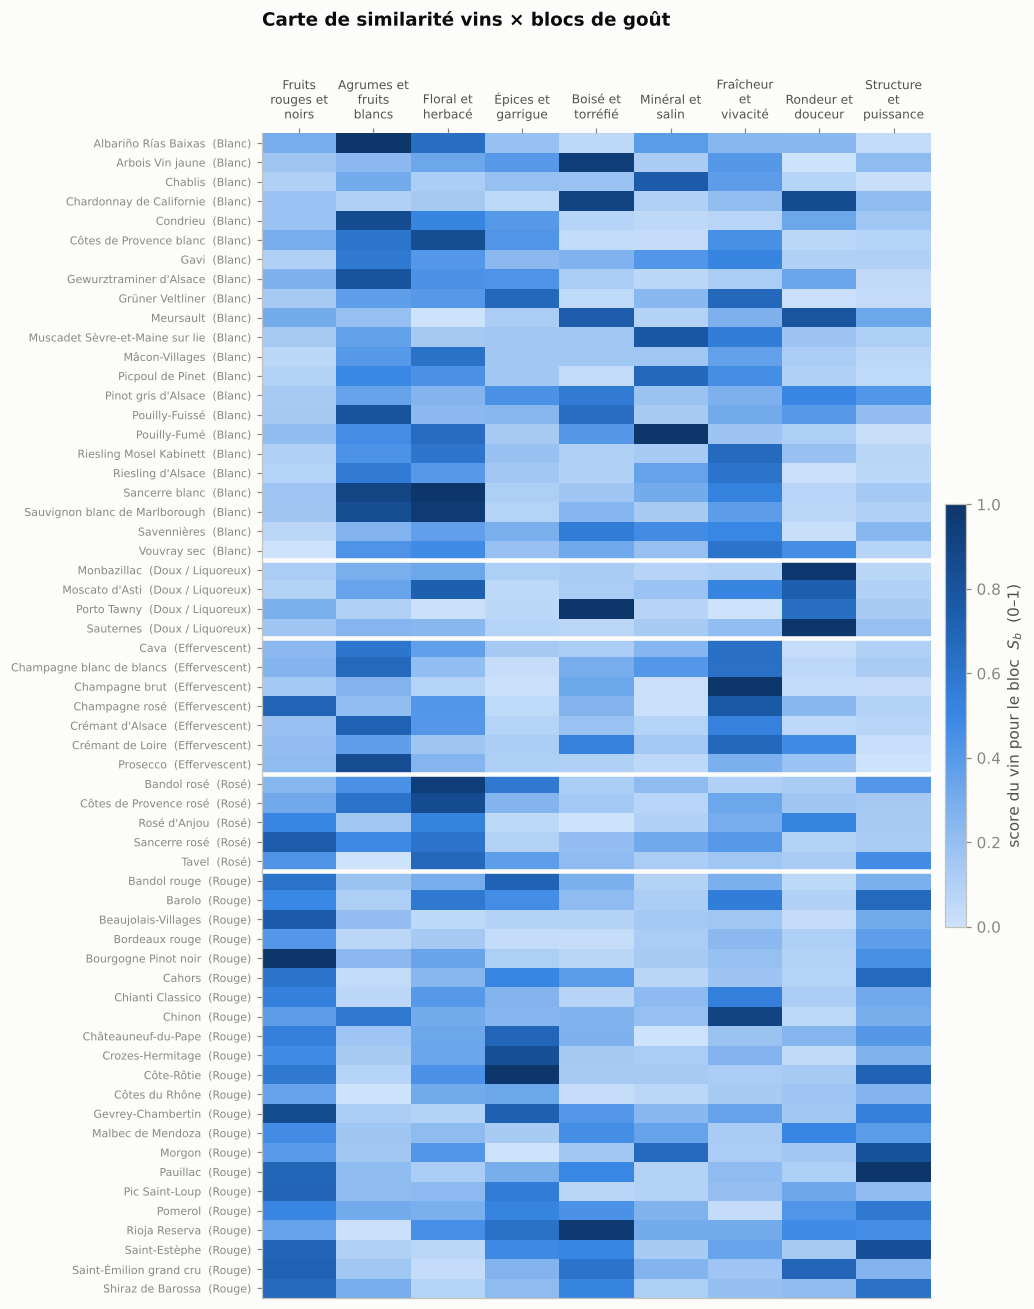

In [ ]:
order = wines.sort_values(["Category", "Name"]).index.to_numpy()
M = eng.S_block[order]
labels = [f"{wines.Name[i]}  ({wines.Category[i]})" for i in order]

fig, ax = plt.subplots(figsize=(9.5, 12))
im = ax.imshow(M, aspect="auto", cmap=SEQ, vmin=0, vmax=1)
ax.set_xticks(range(len(ref.blocks)))
ax.set_xticklabels([textwrap.fill(n, 10) for n in ref.block_names], fontsize=8, color=INK2)
ax.xaxis.tick_top()
ax.set_yticks(range(len(order))); ax.set_yticklabels(labels, fontsize=7.2)
ax.grid(False)
# séparateurs entre catégories
cats_sorted = wines.Category[order].to_numpy()
for k in range(1, len(order)):
    if cats_sorted[k] != cats_sorted[k - 1]:
        ax.axhline(k - 0.5, color=BG, lw=3)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02); cb.set_label("score du vin pour le bloc  $S_b$  (0–1)")
ax.set_title("Carte de similarité vins × blocs de goût", pad=34)
plt.tight_layout(); plt.show()

In [ ]:
top_rows = []
for j, name in enumerate(ref.block_names):
    best = np.argsort(-eng.S_block[:, j])[:3]
    top_rows.append({"Bloc": name, "3 vins les plus proches": " · ".join(wines.Name[i] for i in best)})
display(pd.DataFrame(top_rows))

,Bloc,3 vins les plus proches
0,Fruits rouges et noirs,Bourgogne Pinot noir · Gevrey-Chambertin · Bea...
1,Agrumes et fruits blancs,Albariño Rías Baixas · Sancerre blanc · Condrieu
2,Floral et herbacé,Sancerre blanc · Sauvignon blanc de Marlboroug...
3,Épices et garrigue,Côte-Rôtie · Crozes-Hermitage · Gevrey-Chambertin
4,Boisé et torréfié,Porto Tawny · Rioja Reserva · Arbois Vin jaune
5,Minéral et salin,Pouilly-Fumé · Muscadet Sèvre-et-Maine sur lie...
6,Fraîcheur et vivacité,Champagne brut · Chinon · Champagne rosé
7,Rondeur et douceur,Sauternes · Monbazillac · Chardonnay de Califo...
8,Structure et puissance,Pauillac · Saint-Estèphe · Morgon


## 6 · Axes de structure (sans annotation manuelle)

Les échelles de Likert du questionnaire portent sur 5 axes : **corps, acidité, douceur, tanins, intensité**.
Aucune note n'est saisie dans le jeu de données : la position d'un vin sur un axe vient du texte, par proximité à deux jeux de phrases-pôles (« vin très léger… » / « vin puissant et corsé… »), puis mise à l'échelle [P5, P95] sur le catalogue.

$$d(v) = \overline{\cos(P_v,\ \text{phrases « haut »})} - \overline{\cos(P_v,\ \text{phrases « bas »})}$$

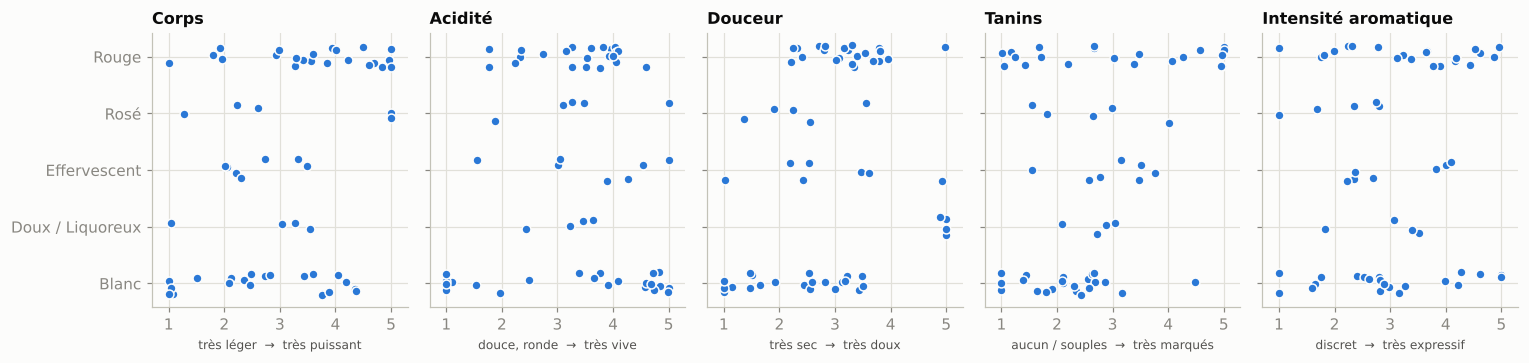

In [ ]:
rng = np.random.default_rng(0)
cats = sorted(wines.Category.unique())
fig, axs = plt.subplots(1, 5, figsize=(14, 3.4), sharey=True)
for ax, key in zip(axs, eng.axis_keys):
    pos = eng.axis_pct[:, eng.axis_keys.index(key)] * 4 + 1          # échelle 1–5 comme les Likert
    for y, c in enumerate(cats):
        m = (wines.Category == c).to_numpy()
        ax.scatter(pos[m], y + rng.uniform(-0.2, 0.2, m.sum()), s=34, color=SERIES[0], edgecolor=BG, linewidth=1, zorder=3)
    ax.set_xlim(0.7, 5.3); ax.set_xticks([1, 2, 3, 4, 5])
    ax.set_title(ref.axes[key]["label"].split(" (")[0], fontsize=10.5)
    ax.set_xlabel(f"{ref.axes[key]['low_label']}  →  {ref.axes[key]['high_label']}", fontsize=8)
axs[0].set_yticks(range(len(cats))); axs[0].set_yticklabels(cats)
plt.tight_layout(); plt.show()

## 7 · Le questionnaire (réponses d'un utilisateur)

L'utilisateur répond à un questionnaire. Dans le notebook, **on remplit directement un objet `UserInput`** : modifiez la cellule suivante et relancez les sections 8 à 12.
Tout champ laissé vide est simplement ignoré par le scoring (les poids sont alors renormalisés).

| Type de question du sujet | Champ |
|---|---|
| Question ouverte (goûts, occasion) | `free_text`, `occasion` |
| Cases à cocher / choix multiple | `liked_blocks`, `avoided_blocks`, `categories`, `countries` |
| Questions guidées | `guided` |
| Contexte mets-vins | `food_type`, `food_text` |
| Échelles de Likert (1–5) | `likert` : `body`, `acidity`, `sweetness`, `tannin`, `intensity` |
| Évaluations de styles (1–5, 3 = neutre) | `style_ratings` : `S1` … `S6` |
| Budget / contraintes | `budget_max`, `categories`, `countries` |

In [ ]:
print("Occasions :", list(ref.occasions))
print("Repas     :", list(ref.food_types))
print("Blocs     :", {b["id"]: b["name"] for b in ref.blocks})
print("Styles    :", {s["id"]: s["text"][:55] + "…" for s in ref.style_cards})

Occasions : ['Apéritif entre amis', 'Repas de fête', 'Dîner romantique', 'Barbecue / grillades', 'Repas du quotidien', 'Cadeau / grande occasion', 'Pique-nique / été']
Repas     : ['Viande rouge / gibier', 'Volaille / viande blanche', 'Poisson', 'Fruits de mer / huîtres', 'Fromages', 'Végétarien / légumes', 'Cuisine épicée / asiatique', 'Charcuterie / apéritif', 'Pâtes / pizza', 'Dessert / fin de repas']
Blocs     : {'B1': 'Fruits rouges et noirs', 'B2': 'Agrumes et fruits blancs', 'B3': 'Floral et herbacé', 'B4': 'Épices et garrigue', 'B5': 'Boisé et torréfié', 'B6': 'Minéral et salin', 'B7': 'Fraîcheur et vivacité', 'B8': 'Rondeur et douceur', 'B9': 'Structure et puissance'}
Styles    : {'S1': 'Un vin frais, vif et citronné, avec des notes minérales…', 'S2': 'Un rouge puissant et tannique, aux arômes de fruits noi…', 'S3': 'Un vin rond, onctueux et gourmand, avec des notes de va…', 'S4': 'Un vin léger et fruité, sur la fraise et la cerise, fac…', 'S5': "Un vin doux et parfumé, sur le

In [ ]:
inp = UserInput(
    free_text="un rouge poivré et fruité, pas trop lourd, pour un barbecue entre amis",
    occasion="Barbecue / grillades",
    liked_blocks=["B1", "B4"],              # fruits rouges/noirs, épices/garrigue
    avoided_blocks=["B5"],                  # boisé/torréfié à éviter
    food_type="Viande rouge / gibier",
    food_text="côte de bœuf grillée",
    likert={"body": 4, "acidity": 3, "tannin": 3},
    style_ratings={"S2": 5, "S3": 4, "S1": 2},
    budget_max=40,
)
liked, avoided = eng.resolve_blocks(inp)
bn = dict(zip(ref.block_ids, ref.block_names))
print("Blocs aimés  :", [bn[b] for b in liked])
print("Blocs évités :", [bn[b] for b in avoided])
print("Texte envoyé à l'encodeur (goûts) :", eng.taste_text(inp))
print("Texte envoyé à l'encodeur (repas) :", eng.food_text(inp))

Blocs aimés  : ['Fruits rouges et noirs', 'Épices et garrigue']
Blocs évités : ['Boisé et torréfié']
Texte envoyé à l'encodeur (goûts) : un rouge poivré et fruité, pas trop lourd, pour un barbecue entre amis. un vin généreux et fruité pour un barbecue entre amis. fraise, cerise, framboise, cassis, mûre, myrtille. poivre noir, poivre blanc, réglisse, clou de girofle, cannelle
Texte envoyé à l'encodeur (repas) : viande rouge grillée ou en sauce, côte de bœuf, gigot d'agneau, gibier. côte de bœuf grillée


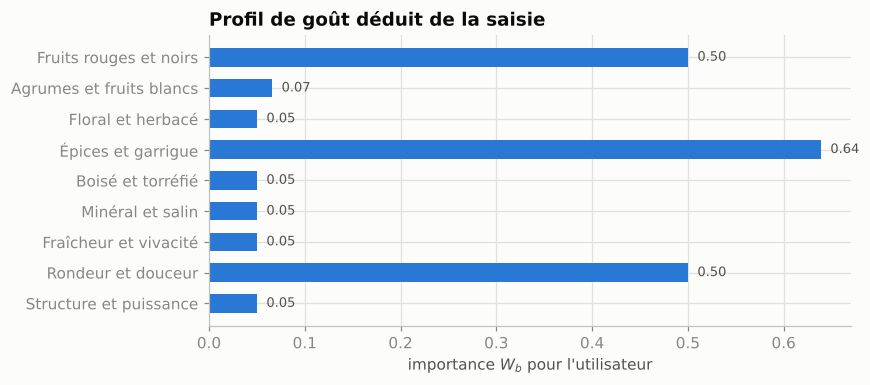

In [ ]:
W = eng.block_weights(inp)          # importance W_b de chaque bloc pour cet utilisateur
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(ref.block_names[::-1], W[::-1], color=SERIES[0], height=0.6)
ax.set_xlabel("importance $W_b$ pour l'utilisateur"); ax.set_title("Profil de goût déduit de la saisie")
for y, v in enumerate(W[::-1]):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=8.5, color=INK2)
plt.tight_layout(); plt.show()

**Comment est calculé $W_b$ ?** Similarité du texte libre/occasion aux phrases du bloc (min-max puis **carré**, pour ne garder que les blocs saillants), mélangée à 50 % avec les cases cochées ; plancher à 0,05 pour éviter un dénominateur nul.

## 8 · Recommandation

`eng.recommend(inp)` renvoie le classement, le **profil détecté** et les composantes du score. Budget, catégorie et pays sont des **filtres durs** : ils éliminent des vins avant le classement.

In [ ]:
SHOW = ["Rank", "Name", "Category", "Region", "PriceEUR", "Score", "Level"]

def show_reco(user, n=5):
    r = eng.recommend(user)
    print(r.summary)
    for w in r.warnings:
        print("⚠", w)
    print(f"{r.n_candidates}/{r.n_total} vins après filtres durs · composantes utilisées : {', '.join(r.present)}")
    display(r.table.head(n)[SHOW].assign(Score=lambda d: d.Score.round(3)))
    return r

res = show_reco(inp, n=10)

Profil détecté — dominante « Épices et garrigue », « Fruits rouges et noirs », « Rondeur et douceur » ; style puissant et corsé ; à éviter : Boisé et torréfié ; repas : viande rouge / gibier ; occasion : barbecue / grillades ; budget ≤ 40 €.
48/60 vins après filtres durs · composantes utilisées : text, coverage, food, structure, pref


,Rank,Name,Category,Region,PriceEUR,Score,Level
0,1,Pic Saint-Loup,Rouge,Languedoc,16,0.651,Bonne affinité
1,2,Châteauneuf-du-Pape,Rouge,Vallée du Rhône (sud),40,0.614,Bonne affinité
2,3,Crozes-Hermitage,Rouge,Vallée du Rhône (nord),21,0.607,Bonne affinité
3,4,Bandol rouge,Rouge,Provence,32,0.544,Bonne affinité
4,5,Côtes du Rhône,Rouge,Vallée du Rhône,8,0.487,Affinité partielle
5,6,Beaujolais-Villages,Rouge,Beaujolais,9,0.462,Affinité partielle
6,7,Bourgogne Pinot noir,Rouge,Bourgogne,22,0.450,Affinité partielle
7,8,Malbec de Mendoza,Rouge,Mendoza (Argentine),13,0.447,Affinité partielle
8,9,Shiraz de Barossa,Rouge,Barossa (Australie),26,0.381,Affinité partielle
9,10,Cahors,Rouge,Sud-Ouest,14,0.376,Affinité partielle


### Un second profil, pour vérifier que le système réagit

Un profil très différent (blanc vif et minéral, fruits de mer) doit donner un classement très différent.

In [ ]:
inp_b = UserInput(
    free_text="un vin blanc vif et minéral qui sent la mer",
    occasion="Apéritif entre amis",
    liked_blocks=["B6", "B7"],
    avoided_blocks=["B5"],
    food_type="Fruits de mer / huîtres",
    likert={"acidity": 5, "body": 2},
    style_ratings={"S1": 5},
    budget_max=35,
)
res_b = show_reco(inp_b, n=5)

Profil détecté — dominante « Fraîcheur et vivacité », « Minéral et salin », « Agrumes et fruits blancs » ; style vif et tendu, léger ; à éviter : Boisé et torréfié ; repas : fruits de mer / huîtres ; occasion : apéritif entre amis ; budget ≤ 35 €.
45/60 vins après filtres durs · composantes utilisées : text, coverage, food, structure, pref


,Rank,Name,Category,Region,PriceEUR,Score,Level
0,1,Picpoul de Pinet,Blanc,Languedoc,8,0.810,Très bonne affinité
1,2,Muscadet Sèvre-et-Maine sur lie,Blanc,Loire (Nantais),8,0.769,Très bonne affinité
2,3,Chablis,Blanc,Bourgogne (Chablis),24,0.693,Bonne affinité
3,4,Albariño Rías Baixas,Blanc,Galice (Espagne),15,0.685,Bonne affinité
4,5,Riesling d'Alsace,Blanc,Alsace,15,0.680,Bonne affinité


## 9 · Le score, pas à pas

On recalcule **à la main** le score du vin classé n° 1 et on vérifie qu'on retrouve exactement la valeur du moteur.

### 9.1 · Score de couverture par blocs

$$\text{Couverture}(v) = \frac{\sum_b W_b \cdot S_b(v)}{\sum_b W_b}$$

C'est une moyenne des scores du vin sur chaque bloc, **pondérée par l'importance que l'utilisateur accorde à ce bloc** : un vin est bien noté s'il est bon sur ce qui compte pour lui.

In [ ]:
top = res.table.iloc[0]
i = int(top["idx"])
S, Wb = eng.S_block[i], res.block_weights
print(f"Vin n°1 : {top['Name']}  ({top['Category']}, {top['Region']})\n")

cov_table = pd.DataFrame({
    "Bloc": ref.block_names,
    "Wb (importance)": Wb.round(3),
    "Sb (vin)": S.round(3),
    "Wb × Sb": (Wb * S).round(3),
})
display(cov_table)
cov = (Wb * S).sum() / Wb.sum()
print(f"Σ Wb·Sb = {(Wb * S).sum():.3f}   Σ Wb = {Wb.sum():.3f}   →   couverture = {cov:.3f}")
assert abs(cov - top["s_coverage"]) < 1e-9
print("✔ identique à la valeur calculée par le moteur")

Vin n°1 : Pic Saint-Loup  (Rouge, Languedoc)



,Bloc,Wb (importance),Sb (vin),Wb × Sb
0,Fruits rouges et noirs,0.500,0.700,0.350
1,Agrumes et fruits blancs,0.066,0.212,0.014
2,Floral et herbacé,0.050,0.229,0.011
3,Épices et garrigue,0.639,0.562,0.359
4,Boisé et torréfié,0.050,0.068,0.003
5,Minéral et salin,0.050,0.089,0.004
6,Fraîcheur et vivacité,0.050,0.199,0.010
7,Rondeur et douceur,0.500,0.327,0.164
8,Structure et puissance,0.050,0.220,0.011


Σ Wb·Sb = 0.927   Σ Wb = 1.955   →   couverture = 0.474
✔ identique à la valeur calculée par le moteur


### 9.2 · Agrégation des cinq composantes

Chaque composante est ramenée sur $[0,1]$ (min-max sur le catalogue, sauf la structure) puis agrégée :

$$\text{Affinité}(v)=\frac{\sum_{c\in\text{renseignées}}\omega_c\, s_c(v)}{\sum_{c\in\text{renseignées}}\omega_c}\qquad\qquad \text{Score}(v)=\max\bigl(0,\ \text{Affinité}(v)-0{,}30\times\text{Pénalité}(v)\bigr)$$

| Composante $c$ | Calcul | Poids par défaut $\omega_c$ |
|---|---|---|
| Affinité sémantique | cos(texte goûts/occasion/familles cochées, profil du vin) | 0,30 |
| Couverture des blocs | formule ci-dessus | 0,25 |
| Accord mets-vins | cos(texte du repas, champ `FoodPairing`) | 0,20 |
| Structure (Likert) | $1-\lvert \text{cible} - \text{position}\rvert$ moyenné sur les axes renseignés | 0,15 |
| Préférences de style | $\sum (\text{note}-3)\cos(v,\text{carte}) / \sum\lvert \text{note}-3\rvert$ | 0,10 |

La **pénalité** est la couverture moyenne des blocs que l'utilisateur veut éviter : une préférence négative est rarement absolue, on pénalise sans exclure.

In [ ]:
rows = []
for c in res.present:
    s_c = top[f"s_{c}"]
    rows.append({
        "Composante": COMPONENT_LABELS[c],
        "Note s_c (0–1)": round(s_c, 3),
        "Poids par défaut": DEFAULT_WEIGHTS[c],
        "Poids effectif (renormalisé)": round(res.weights[c], 3),
        "Contribution ω·s": round(res.weights[c] * s_c, 3),
    })
comp = pd.DataFrame(rows)
display(comp)

affinity = sum(res.weights[c] * top[f"s_{c}"] for c in res.present)
penalty = top["Penalty"]
final = float(np.clip(affinity - AVOID_GAMMA * penalty, 0, 1))
print(f"Affinité  = Σ ω·s                 = {affinity:.3f}")
print(f"Pénalité  = couverture moyenne des blocs évités = {penalty:.3f}  →  − {AVOID_GAMMA} × {penalty:.3f} = {-AVOID_GAMMA * penalty:.3f}")
print(f"Score     = {final:.3f}   →   niveau : {level_of(final)}")
assert abs(final - top["Score"]) < 1e-9
print("✔ identique au score du moteur")

,Composante,Note s_c (0–1),Poids par défaut,Poids effectif (renormalisé),Contribution ω·s
0,Affinité sémantique (texte libre),0.691,0.30,0.30,0.207
1,Couverture des blocs de goût,0.474,0.25,0.25,0.119
2,Accord mets-vins,0.763,0.20,0.20,0.153
3,Structure (échelles de Likert),0.799,0.15,0.15,0.120
4,Préférences de style (notes),0.737,0.10,0.10,0.074


Affinité  = Σ ω·s                 = 0.672
Pénalité  = couverture moyenne des blocs évités = 0.068  →  − 0.3 × 0.068 = -0.021
Score     = 0.651   →   niveau : Bonne affinité
✔ identique au score du moteur


### 9.3 · Pourquoi les poids sont renormalisés

Si l'utilisateur ne renseigne pas une question (par exemple pas de Likert), la composante correspondante est **exclue** et les poids restants sont divisés par leur somme : un champ vide ne pénalise jamais un vin.

### 9.4 · Niveaux d'affinité

$\ge 0{,}70$ : *très bonne affinité* · $0{,}50$–$0{,}70$ : *bonne* · sinon *partielle*.

> **À retenir sur l'interprétation.** Le min-max rend les scores **relatifs au catalogue** : « 1 » signifie « le plus proche parmi les 60 vins pour cette requête », pas « correspond à 100 % ». Les seuils ne sont donc pas absolus et ne se comparent pas d'un backend à l'autre.

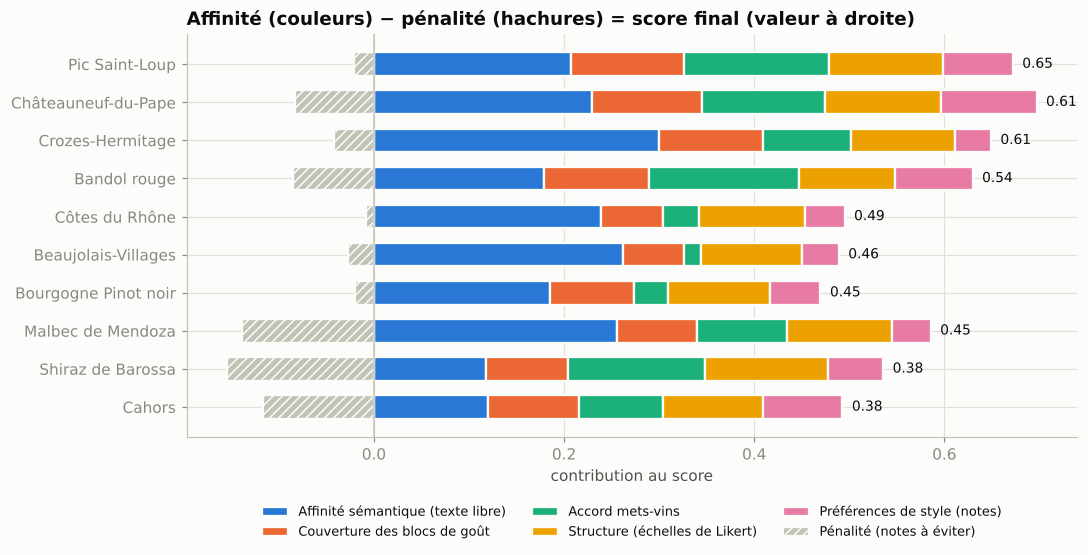

In [ ]:
# Décomposition du score des 10 premiers vins : contribution de chaque composante (+ pénalité en négatif)
t10 = res.table.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.2))
left = np.zeros(len(t10))
for k, c in enumerate(res.present):
    vals = t10[f"contrib_{c}"].to_numpy()
    ax.barh(t10["Name"], vals, left=left, height=0.62, color=SERIES[k % 5], edgecolor=BG, linewidth=1.5, label=COMPONENT_LABELS[c])
    left += vals
pen = t10["contrib_penalty"].to_numpy()
ax.barh(t10["Name"], pen, height=0.62, color=GRAY, edgecolor=BG, linewidth=1.5, hatch="////", label="Pénalité (notes à éviter)")
for y, (s_, l_) in enumerate(zip(t10["Score"], left)):
    ax.text(l_ + 0.01, y, f"{s_:.2f}", va="center", fontsize=9, color=INK)
ax.axvline(0, color=AXIS, lw=1)
ax.set_xlabel("contribution au score")
ax.set_title("Affinité (couleurs) − pénalité (hachures) = score final (valeur à droite)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize=8.5)
plt.tight_layout(); plt.show()

## 10 · Explications : pourquoi ce vin ?

Pour chaque vin, le moteur cite les blocs qui y contribuent le plus, les cosinus utilisés et l'écart entre structure souhaitée et structure du vin.

In [ ]:
for _, row in res.table.head(3).iterrows():
    print(f"#{row['Rank']}  {row['Name']} — {row['Category']}, {row['Region']}, {row['PriceEUR']} €  |  score {row['Score']:.2f}  ({row['Level']})")
    for line in eng.explain(res, int(row["idx"])):
        print("   •", line)
    print()

#1  Pic Saint-Loup — Rouge, Languedoc, 16 €  |  score 0.65  (Bonne affinité)
   • Bloc « Épices et garrigue » : couverture 56% (importance pour vous 100%) — notes proches : « réglisse, clou de girofle, cannelle ».
   • Bloc « Fruits rouges et noirs » : couverture 70% (importance pour vous 78%) — notes proches : « confiture de fruits noirs ».
   • Accord mets-vins : cosinus 0.66 entre votre repas et « grillades, cassoulet léger, tajine d'agneau, burgers gourmets, fromages de brebis ».
   • Texte libre : cosinus 0.35 avec le profil gustatif du vin.
   • Corps : souhaité 4/5, profil du vin ≈ 3.9/5.
   • Acidité : souhaité 3/5, profil du vin ≈ 4.1/5.
   • Tanins : souhaité 3/5, profil du vin ≈ 1.7/5.

#2  Châteauneuf-du-Pape — Rouge, Vallée du Rhône (sud), 40 €  |  score 0.61  (Bonne affinité)
   • Bloc « Épices et garrigue » : couverture 69% (importance pour vous 100%) — notes proches : « thym, romarin, garrigue, herbes de Provence ».
   • Bloc « Fruits rouges et noirs » : couverture 54% 

## 11 · Visualisations

### 11.1 · Radar : le profil de l'utilisateur face aux meilleurs vins

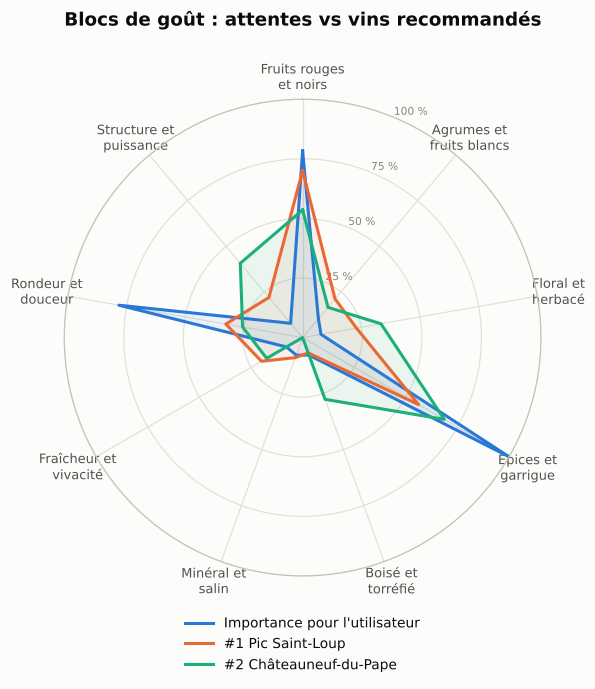

In [ ]:
def radar(ax, labels, series):
    n = len(labels)
    ang = np.linspace(0, 2 * np.pi, n, endpoint=False)
    ang = np.r_[ang, ang[:1]]
    ax.set_theta_offset(np.pi / 2); ax.set_theta_direction(-1)
    ax.set_xticks(ang[:-1]); ax.set_xticklabels([textwrap.fill(l, 13) for l in labels], fontsize=8.5, color=INK2)
    ax.set_ylim(0, 1); ax.set_yticks([0.25, 0.5, 0.75, 1]); ax.set_yticklabels(["25 %", "50 %", "75 %", "100 %"], fontsize=7, color=MUTED)
    ax.grid(color=GRID); ax.spines["polar"].set_color(AXIS)
    for name, vals, color in series:
        v = np.r_[vals, vals[:1]]
        ax.plot(ang, v, color=color, lw=2, label=name)
        ax.fill(ang, v, color=color, alpha=0.08)

t1, t2 = res.table.iloc[0], res.table.iloc[1]
fig = plt.figure(figsize=(7.4, 6.4))
ax = fig.add_subplot(111, polar=True)
radar(ax, ref.block_names, [
    ("Importance pour l'utilisateur", res.block_weights / res.block_weights.max(), SERIES[0]),
    (f"#1 {t1['Name']}", eng.S_block[int(t1["idx"])], SERIES[1]),
    (f"#2 {t2['Name']}", eng.S_block[int(t2["idx"])], SERIES[2]),
])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=1)
ax.set_title("Blocs de goût : attentes vs vins recommandés", pad=24)
plt.tight_layout(); plt.show()

### 11.2 · Carte sémantique du catalogue (PCA) et clusters

Les 60 profils de vins sont projetés en 2D par **PCA** ; un **K-means (k = 6)** sur les embeddings regroupe les vins sémantiquement proches (C1 à C6). L'étoile est la position de la saisie de l'utilisateur dans le même espace.

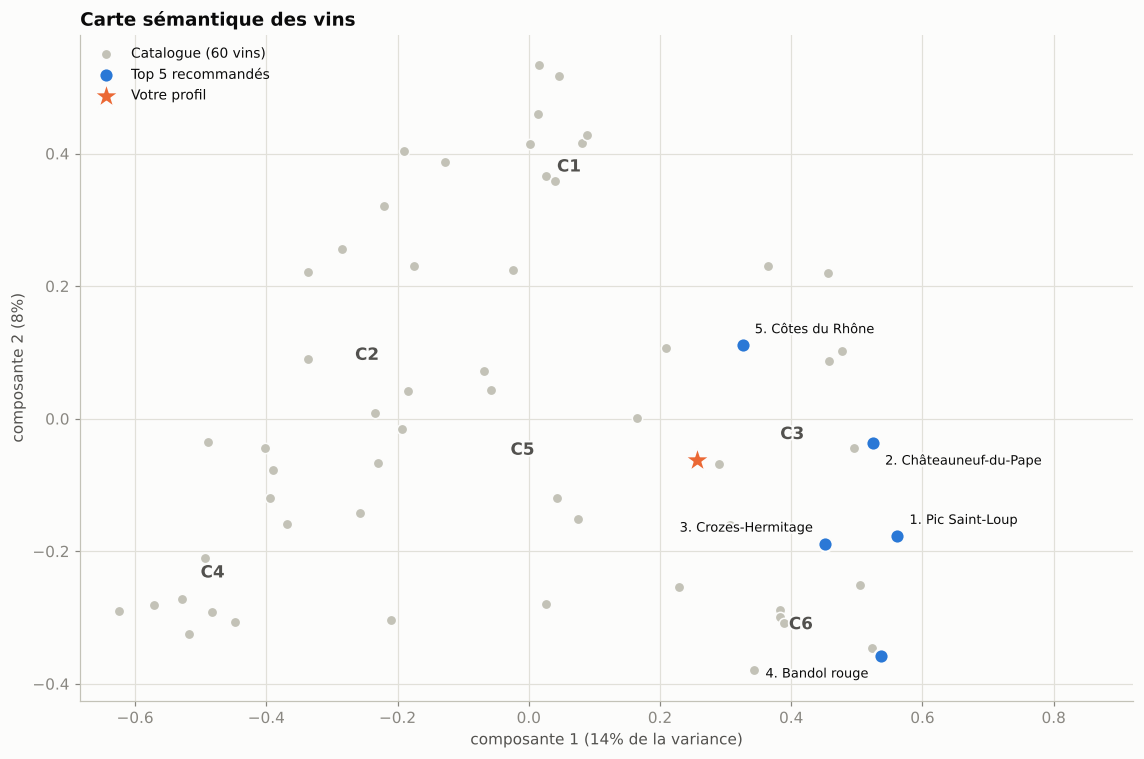

,Cluster,Vins,Exemples
0,C1 · Blancs — Rondeur et douceur + Boisé et to...,10,"Rioja Reserva, Meursault, Gewurztraminer d'Als..."
1,C2 · Mixte — Fraîcheur et vivacité + Agrumes e...,14,"Chinon, Pouilly-Fuissé, Mâcon-Villages, Pouill..."
2,C3 · Rouges — Fruits rouges et noirs + Structu...,12,"Saint-Émilion grand cru, Pomerol, Bordeaux rou..."
3,C4 · Blancs — Agrumes et fruits blancs + Minér...,10,"Chablis, Sancerre blanc, Muscadet Sèvre-et-Mai..."
4,C5 · Rosés — Floral et herbacé + Fruits rouges...,7,"Bourgogne Pinot noir, Côtes de Provence rosé, ..."
5,C6 · Rouges — Structure et puissance + Fruits ...,7,"Saint-Estèphe, Pauillac, Gevrey-Chambertin, Ca..."


In [ ]:
df_map, upos = eng.map_frame(res.user_vec)
fig, ax = plt.subplots(figsize=(10.5, 7))
ax.scatter(df_map["x"], df_map["y"], s=46, color=GRAY, edgecolor=BG, linewidth=1, zorder=2, label="Catalogue (60 vins)")

top5 = res.table.head(5)
xy5 = eng.xy[top5["idx"].astype(int).to_numpy()]
ax.scatter(xy5[:, 0], xy5[:, 1], s=90, color=SERIES[0], edgecolor=BG, linewidth=1.5, zorder=3, label="Top 5 recommandés")
OFFSETS = [(8, 8, "left"), (8, -14, "left"), (-8, 8, "right"), (-8, -14, "right"), (8, 8, "left")]   # évite les collisions
for k_, ((_, r_), (x_, y_)) in enumerate(zip(top5.iterrows(), xy5)):
    dx, dy, ha_ = OFFSETS[k_ % len(OFFSETS)]
    ax.annotate(f"{r_['Rank']}. {r_['Name']}", (x_, y_), xytext=(dx, dy), textcoords="offset points", ha=ha_, fontsize=8.5, color=INK, path_effects=HALO, zorder=5)
if upos is not None:
    ax.scatter(*upos, marker="*", s=300, color=SERIES[1], edgecolor=BG, linewidth=1.2, zorder=4, label="Votre profil")
for c in range(len(eng.cluster_names)):
    cx, cy = eng.xy[eng.cluster == c].mean(axis=0)
    ax.text(cx, cy, f"C{c + 1}", fontsize=11, fontweight="bold", color=INK2, ha="center", va="center", path_effects=HALO, zorder=6)
ev_ = eng.pca.explained_variance_ratio_
ax.set_xlabel(f"composante 1 ({ev_[0]:.0%} de la variance)"); ax.set_ylabel(f"composante 2 ({ev_[1]:.0%})")
ax.set_xlim(ax.get_xlim()[0], ax.get_xlim()[1] + 0.3)
ax.set_title("Carte sémantique des vins"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

cl = pd.DataFrame({"Cluster": eng.cluster_names,
                   "Vins": [int((eng.cluster == c).sum()) for c in range(len(eng.cluster_names))],
                   "Exemples": [", ".join(wines.Name[eng.cluster == c].head(4)) + " …" for c in range(len(eng.cluster_names))]})
display(cl)

## 12 · Sensibilité aux pondérations et filtres durs

Les poids $\omega_c$ ne sont **pas appris** (pas de données d'usage) : ils sont fixés par jugement (le texte libre est le signal le plus riche) et ajustables. Voici ce qui change dans le top 5 quand on les modifie.

In [ ]:
scenarios = {
    "Défaut (0,30 / 0,25 / 0,20 / 0,15 / 0,10)": None,
    "Tout sur le texte libre": {"text": 1, "coverage": 0, "food": 0, "structure": 0, "pref": 0},
    "Tout sur la couverture": {"text": 0, "coverage": 1, "food": 0, "structure": 0, "pref": 0},
    "Tout sur l'accord mets-vins": {"text": 0, "coverage": 0, "food": 1, "structure": 0, "pref": 0},
    "Poids égaux": {k: 0.2 for k in DEFAULT_WEIGHTS},
}
base_top5 = list(eng.recommend(inp).table.head(5)["Name"])
rows = []
for label, w in scenarios.items():
    t5 = list(eng.recommend(replace(inp, weights=w)).table.head(5)["Name"])
    rows.append({"Scénario": label, "Top 5": " · ".join(t5), "Communs avec le défaut": len(set(t5) & set(base_top5))})
display(pd.DataFrame(rows))

,Scénario,Top 5,Communs avec le défaut
0,"Défaut (0,30 / 0,25 / 0,20 / 0,15 / 0,10)",Pic Saint-Loup · Châteauneuf-du-Pape · Crozes-...,5
1,Tout sur le texte libre,Crozes-Hermitage · Beaujolais-Villages · Côtes...,3
2,Tout sur la couverture,Pic Saint-Loup · Crozes-Hermitage · Châteauneu...,4
3,Tout sur l'accord mets-vins,Pic Saint-Loup · Bandol rouge · Châteauneuf-du...,4
4,Poids égaux,Pic Saint-Loup · Châteauneuf-du-Pape · Bandol ...,5


In [ ]:
# Filtres durs : ils retirent des vins du classement sans modifier les scores des autres
tests = {
    "Aucun filtre": replace(inp, budget_max=None),
    "Budget ≤ 20 €": replace(inp, budget_max=20),
    "Catégorie Rouge + budget ≤ 40 €": replace(inp, categories=["Rouge"]),
    "Pays : France uniquement": replace(inp, countries=["France"]),
}
rows = []
for label, u in tests.items():
    r = eng.recommend(u)
    rows.append({"Filtre": label, "Vins restants": f"{r.n_candidates}/{r.n_total}", "Top 3": " · ".join(r.table.head(3)["Name"])})
display(pd.DataFrame(rows))

,Filtre,Vins restants,Top 3
0,Aucun filtre,60/60,Côte-Rôtie · Pic Saint-Loup · Châteauneuf-du-Pape
1,Budget ≤ 20 €,36/60,Pic Saint-Loup · Côtes du Rhône · Beaujolais-V...
2,Catégorie Rouge + budget ≤ 40 €,16/60,Pic Saint-Loup · Châteauneuf-du-Pape · Crozes-...
3,Pays : France uniquement,34/60,Pic Saint-Loup · Châteauneuf-du-Pape · Crozes-...


## 13 · Évaluation des backends

**Protocole** (`evaluate.py`) : 19 requêtes en français — 13 *directes* (vocabulaire proche du jeu de données) et 6 *paraphrases* volontairement éloignées (« un vin qui sent la mer » pour « salin, iodé »). Pour chaque requête, l'ensemble des vins pertinents a été annoté à la main **avant** de lancer les calculs. Métriques : **P@5** (part de pertinents dans le top 5), **Hit@1** (le n°1 est pertinent), **MRR** (inverse du rang du premier pertinent).

> ⚠ Un seul annotateur, 19 requêtes : c'est un **test de cohérence, pas un benchmark**.

La baseline « mots-clés » (TF-IDF brut) sert de point de comparaison : un système sémantique n'a d'intérêt que s'il fait mieux dès que le vocabulaire s'éloigne.

In [ ]:
# Moteurs disponibles : chaque backend indisponible est ignoré proprement (SBERT absent, modèle spaCy non installé…)
engines = {}
for name in ["sbert", "spacy", "lsa"]:
    if name == backend.name:
        engines[name] = eng
        continue
    b, n = load_backend(name)
    if b.name != name:
        print(f"⚠ backend « {name} » indisponible → ignoré")
        continue
    engines[name] = WineEngine(wines, ref, b)
print("Backends évalués :", [e.backend.label for e in engines.values()])

rows = []
kw = ev.keyword_baseline(wines)
for grp, q, rel in ev.QUERIES:
    ranked = [wines.Name[i] for i in np.argsort(-kw(q))]
    rows.append(("kw", "Mots-clés (TF-IDF brut)", grp, q, *ev.metrics(ranked, rel)))
for name, e in engines.items():
    for grp, q, rel in ev.QUERIES:
        ranked = ev.ranking(e, UserInput(free_text=q))
        rows.append((name, e.backend.label, grp, q, *ev.metrics(ranked, rel)))
res_eval = pd.DataFrame(rows, columns=["key", "Backend", "Groupe", "Requête", "P@5", "Hit@1", "MRR"])
summary = res_eval.groupby(["key", "Backend", "Groupe"], sort=False)[["P@5", "Hit@1", "MRR"]].mean().round(3).reset_index()
display(summary.drop(columns="key"))

⚠ backend « sbert » indisponible → ignoré
⚠ backend « spacy » indisponible → ignoré
Backends évalués : ['LSA · TF-IDF + SVD (hors-ligne)']


,Backend,Groupe,P@5,Hit@1,MRR
0,Mots-clés (TF-IDF brut),directes,0.569,0.846,0.904
1,Mots-clés (TF-IDF brut),paraphrases,0.333,0.500,0.658
2,LSA · TF-IDF + SVD (hors-ligne),directes,0.600,0.846,0.891
3,LSA · TF-IDF + SVD (hors-ligne),paraphrases,0.500,0.667,0.722


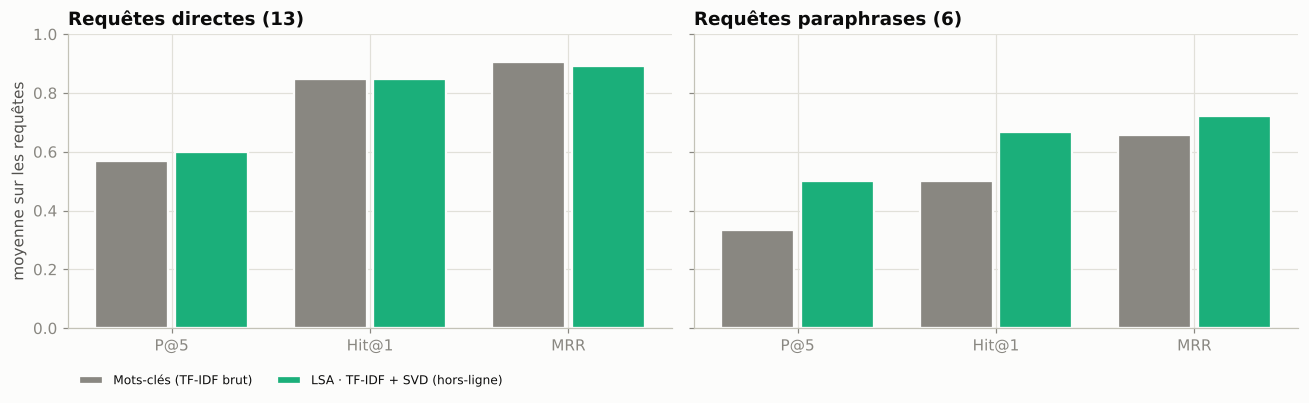

In [ ]:
COLORS = {"kw": MUTED, "sbert": SERIES[0], "spacy": SERIES[1], "lsa": SERIES[2]}      # couleur = entité, jamais le rang
metrics_ = ["P@5", "Hit@1", "MRR"]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, grp in zip(axs, ["directes", "paraphrases"]):
    sub = summary[summary["Groupe"] == grp]
    nb = len(sub); w = 0.8 / nb
    for k, (_, r_) in enumerate(sub.iterrows()):
        ax.bar(np.arange(3) + (k - (nb - 1) / 2) * w, [r_[m] for m in metrics_], width=w * 0.92,
               color=COLORS[r_["key"]], edgecolor=BG, linewidth=1.5, label=r_["Backend"])
    ax.set_xticks(range(3)); ax.set_xticklabels(metrics_); ax.set_ylim(0, 1)
    ax.set_title(f"Requêtes {grp} ({'13' if grp == 'directes' else '6'})")
axs[0].set_ylabel("moyenne sur les requêtes")
axs[0].legend(loc="upper left", fontsize=8, bbox_to_anchor=(0, -0.12), ncol=2)
plt.tight_layout(); plt.show()

In [ ]:
# Cohérence des axes de structure : AUC = probabilité qu'un vin « haut » soit placé au-dessus d'un vin « bas » (0,5 = hasard, 1 = parfait)
def axis_auc(e):
    idx = {n_: i for i, n_ in enumerate(e.wines.Name)}
    cat_ = e.wines["Category"].to_numpy()
    truth = {**{k: ([idx[x] for x in p], [idx[x] for x in n_]) for k, (p, n_) in ev.AXIS_TRUTH.items()},
             "sweetness": (list(np.where(cat_ == "Doux / Liquoreux")[0]), list(np.where(cat_ != "Doux / Liquoreux")[0])),
             "tannin": ([idx[x] for x in ["Saint-Estèphe", "Pauillac", "Cahors", "Barolo", "Bandol rouge", "Shiraz de Barossa"]],
                        sorted(set(np.where(cat_ != "Rouge")[0]) | {idx["Beaujolais-Villages"], idx["Bourgogne Pinot noir"]}))}
    return {k: round(ev.auc(e.axis_pct[:, e.axis_keys.index(k)], *truth[k]), 2) for k in truth}

display(pd.DataFrame([{"Backend": e.backend.label, **axis_auc(e)} for e in engines.values()]))

,Backend,body,acidity,sweetness,tannin
0,LSA · TF-IDF + SVD (hors-ligne),1.0,1.0,0.99,0.94


**Lecture.** Comparez d'abord les *paraphrases* : c'est là qu'un espace sémantique doit se distinguer des mots-clés. Sur les requêtes directes, le jeu de données et les requêtes partagent beaucoup de vocabulaire, donc la baseline est déjà forte.
Les vecteurs de mots moyennés (spaCy) ignorent le contexte (ils ont par exemple remonté « Côte-Rôtie » pour « côte de bœuf »). Une requête dont aucun mot n'est connu de LSA ou de spaCy ne renvoie rien (le moteur le signale) ; SBERT n'a pas cette limite.

> Si la ligne **SBERT** n'apparaît pas, installez `sentence-transformers` (connexion Internet requise au premier lancement), relancez le notebook : SBERT est alors utilisé automatiquement et ajouté au tableau.

## 14 · Stockage des réponses, limites et éthique

Le sujet demande un stockage structuré des réponses. Voici l'enregistrement d'une réponse (réponses brutes, profil détecté, top 5) ; mettez `SAVE_RESPONSE = True` pour l'ajouter à `responses/notebook_responses.jsonl`.

In [ ]:
record = {
    "timestamp": pd.Timestamp.now().isoformat(timespec="seconds"),
    "backend": backend.name,
    "answers": inp.to_record(),
    "profile_summary": res.summary,
    "top5": res.table.head(5)[["WineID", "Name", "Score", "Level"]].round(3).to_dict("records"),
}
print(json.dumps(record, ensure_ascii=False, indent=2)[:1800])

SAVE_RESPONSE = False
if SAVE_RESPONSE:
    out = ROOT / "responses"; out.mkdir(exist_ok=True)
    with open(out / "notebook_responses.jsonl", "a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")
    print("→ enregistré dans", out / "notebook_responses.jsonl")

{
  "timestamp": "2026-11-17T19:38:19",
  "backend": "lsa",
  "answers": {
    "free_text": "un rouge poivré et fruité, pas trop lourd, pour un barbecue entre amis",
    "occasion": "Barbecue / grillades",
    "liked_blocks": [
      "B1",
      "B4"
    ],
    "avoided_blocks": [
      "B5"
    ],
    "guided": {},
    "food_type": "Viande rouge / gibier",
    "food_text": "côte de bœuf grillée",
    "likert": {
      "body": 4,
      "acidity": 3,
      "tannin": 3
    },
    "style_ratings": {
      "S2": 5,
      "S3": 4,
      "S1": 2
    },
    "budget_max": 40,
    "categories": [],
    "countries": [],
    "weights": null
  },
  "profile_summary": "Profil détecté — dominante « Épices et garrigue », « Fruits rouges et noirs », « Rondeur et douceur » ; style puissant et corsé ; à éviter : Boisé et torréfié ; repas : viande rouge / gibier ; occasion : barbecue / grillades ; budget ≤ 40 €.",
  "top5": [
    {
      "WineID": "W15",
      "Name": "Pic Saint-Loup",
      "Score": 0.6

### Choix de conception (à reprendre dans le rapport)

- **SBERT multilingue** comme backend principal : les descriptions sont en français et très contextuelles (« tanins soyeux » ≠ « tanins rugueux »).
- **Trois backends derrière une même interface** (SBERT, spaCy, LSA) : comparer des techniques et garantir que le système tourne sans téléchargement.
- **Min-max sur le catalogue** : la plage des cosinus dépend du modèle ; la normalisation rend les composantes additionnables. Contrepartie : des scores *relatifs*.
- **Moyenne des 2 meilleures phrases par bloc**, **profil 0,4 / 0,6**, **pondérations par défaut** fixées par jugement : ajustables, non apprises.
- **Pénalité plutôt qu'exclusion** pour les notes à éviter.
- **Cases cochées et texte** pour l'importance des blocs : signal explicite robuste si le texte est court, sans écraser la nuance du texte.

### Limites

- Jeu de données **fictif et pédagogique** (60 profils types d'appellations rédigés pour le projet, prix indicatifs) : ni guide, ni conseil d'achat.
- Scores **relatifs au catalogue** ; poids **non appris** ; évaluation par un seul annotateur sur 19 requêtes.
- Le texte libre n'est pas reformulé avant encodage ; LSA et spaCy ignorent les mots hors de leur vocabulaire.

### Éthique

Public adulte, aucun lien marchand ni incitation à consommer, aucune donnée de santé demandée, réponses stockées localement (ne pas y saisir d'informations personnelles).

### Pistes (bonus)

Chatbot « sommelier » expliquant un classement (LLM + RAG sur `wines.csv`), reformulation des réponses libres avant encodage, apprentissage des poids à partir de retours utilisateurs, catalogue élargi (≥ 200 vins) pour des clusters plus stables.